<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/actividad_2_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ejercicio 1: K-mean segmentar clientes de una tienda

## Paso 0: Preparar Colab y Descargar Dataset

In [ ]:
import os
from google.colab import userdata
import kagglehub

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Dataset descargado en:", path)
print("Contenido del directorio:", os.listdir(path))

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Dataset descargado en: /kaggle/input/customer-segmentation-tutorial-in-python
Contenido del directorio: ['Mall_Customers.csv']


## Paso 1: Exploración Inicial e Hipótesis antes de Calcular

Graficamos el ingreso anual versus el puntaje de gasto, sin colorear nada, para plantear una hipótesis visual sobre el número de segmentos.

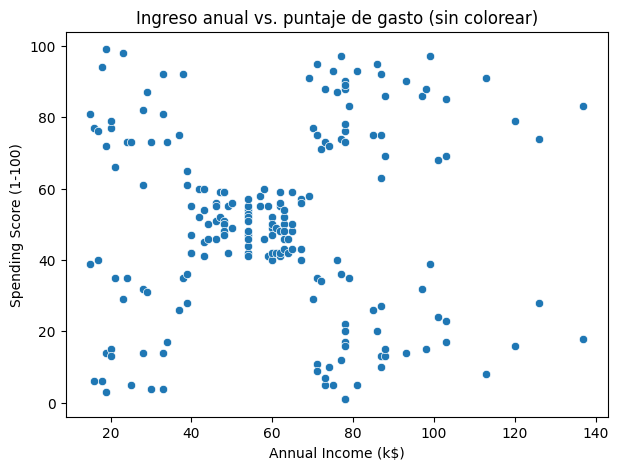

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(os.path.join(path, "Mall_Customers.csv"))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Ingreso anual vs. puntaje de gasto (sin colorear)")
plt.show()

**Observación visual de la nube de puntos:**
Al analizar el gráfico de dispersión de *Ingreso Atractivo* frente a *Puntaje de Gasto*, se identifican visualmente **5 grupos naturales** bien definidos:

1. **Grupo Centro (Ingresos medios, Gastos medios)**
2. **Grupo Superior Izquierdo (Ingresos bajos, Gastos altos)**
3. **Grupo Inferior Izquierdo (Ingresos bajos, Gastos bajos)**
4. **Grupo Superior Derecho (Ingresos altos, Gastos altos)**
5. **Grupo Inferior Derecho (Ingresos altos, Gastos bajos)**

**Evidencia Visual:** Los espacios vacíos entre estas 5 acumulaciones de puntos actúan como fronteras naturales, lo que sugiere fuertemente que un modelo con $k=5$ será el más adecuado.

## Paso 2: Cargar y Explorar (EDA)

In [ ]:
print("Dimensiones del DataFrame:", df.shape)
print("\n--- Información General ---")
df.info()
print("\n--- Valores Nulos por Columna ---")
print(df.isna().sum())
display(df.describe())

Dimensiones del DataFrame: (200, 5)

--- Información General ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

--- Valores Nulos por Columna ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Edad')
sns.boxplot(y=df['Annual Income (k$)'], ax=axes[1], color='lightgreen')
axes[1].set_title('Distribución de Ingreso Anual')
sns.boxplot(y=df['Spending Score (1-100)'], ax=axes[2], color='salmon')
axes[2].set_title('Distribución de Puntaje de Gasto')
plt.tight_layout()
plt.show()

### Decisiones de Diseño y Variables

* **CustomerID:** Se excluye porque es un identificador único que no aporta información sobre el comportamiento y solo añadiría ruido al modelo.
* **Gender:** Se excluye del cálculo inicial de distancia porque al ser una variable binaria (0/1), la distancia euclidiana pierde sentido físico frente a variables continuas como los ingresos o gastos, distorsionando el peso real de los datos.

## Paso 3: Preparación de Variables y Estandarización

* **Rangos iniciales:** Ingreso Anual (15 a 137 k$) y Puntaje de Gasto (1 a 99).
* **Decisión:** Aplicar `StandardScaler` para estandarizar ambas variables.
* **Justificación:** Garantiza que el algoritmo K-Means no se vea sesgado por las diferencias de escala y varianza.

In [ ]:
from sklearn.preprocessing import StandardScaler

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X_unscaled = df[features].copy()

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_unscaled)
X_scaled = pd.DataFrame(X_scaled_array, columns=features)

## Paso 4: Ajustar K-means y Explorar $k$

Evaluamos el comportamiento de K-Means para distintos valores de $k$ (de 2 a 10) utilizando la inercia y el coeficiente de silueta.

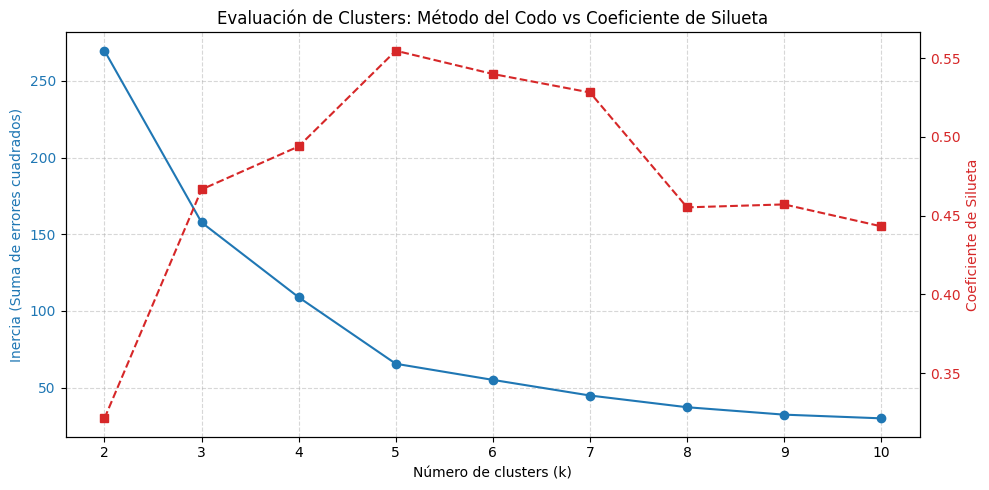

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_range = range(2, 11)
inertias = []
silhouettes = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'tab:blue'
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia (Suma de errores cuadrados)', color=color)
ax1.plot(K_range, inertias, marker='o', color=color, label='Inercia')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Coeficiente de Silueta', color=color)
ax2.plot(K_range, silhouettes, marker='s', color=color, linestyle='--', label='Silueta')
ax2.tick_params(axis='y', labelcolor=color)
plt.title('Evaluación de Clusters: Método del Codo vs Coeficiente de Silueta')
fig.tight_layout()
plt.show()

### Análisis de la Inercia y Selección de $k$

* **¿Por qué disminuye la inercia al aumentar $k$?** Al añadir más centroides, los puntos tienen un centro de gravedad más cercano, reduciendo inevitablemente las distancias internas. Si $k$ es igual al total de datos ($N$), la inercia es cero.
* **Implicación para elegir $k$:** No se puede elegir el número de grupos solo minimizando la inercia, ya que llevaría al sobreajuste ($k=N$). Se debe buscar el punto de inflexión o "codo" donde la ganancia de información decrece, apoyándose siempre en el coeficiente de silueta.

## Paso 5: Evaluar con más de una evidencia

### 1. Robustez de la Estabilidad

In [ ]:
from sklearn.metrics import adjusted_rand_score

kmeans_full = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_full = kmeans_full.fit_predict(X_scaled)

kmeans_seed = KMeans(n_clusters=5, random_state=100, n_init=10)
labels_seed = kmeans_seed.fit_predict(X_scaled)
ari_seed = adjusted_rand_score(labels_full, labels_seed)

df_sample = X_scaled.sample(frac=0.8, random_state=42)
k_sample = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_sample = k_sample.fit_predict(df_sample)
labels_full_subset = labels_full[df_sample.index]
ari_sample = adjusted_rand_score(labels_full_subset, labels_sample)

print(f"Estabilidad ante cambio de semilla (ARI): {ari_seed:.4f} (1.0 es idéntico)")
print(f"Estabilidad ante submuestreo del 80% (ARI): {ari_sample:.4f}")

Estabilidad ante cambio de semilla (ARI): 1.0000 (1.0 es idéntico)
Estabilidad ante submuestreo del 80% (ARI): 0.9807


### 2. Mini-Experimento de Escala: Con vs Sin Estandarizar

In [ ]:
kmeans_unscaled = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_unscaled = kmeans_unscaled.fit_predict(X_unscaled)
tabla_comparativa = pd.crosstab(labels_unscaled, labels_full, rownames=['Sin Escalar'], colnames=['Escalado'])
display(tabla_comparativa)
ari_escala = adjusted_rand_score(labels_unscaled, labels_full)
print(f"\nÍndice de Rand Ajustado (ARI) entre escalado y sin escalar: {ari_escala:.4f}")

Escalado,0,1,2,3,4
Sin Escalar,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23



Índice de Rand Ajustado (ARI) entre escalado y sin escalar: 1.0000


## Paso 6: Interpretar, Graficar y Decidir

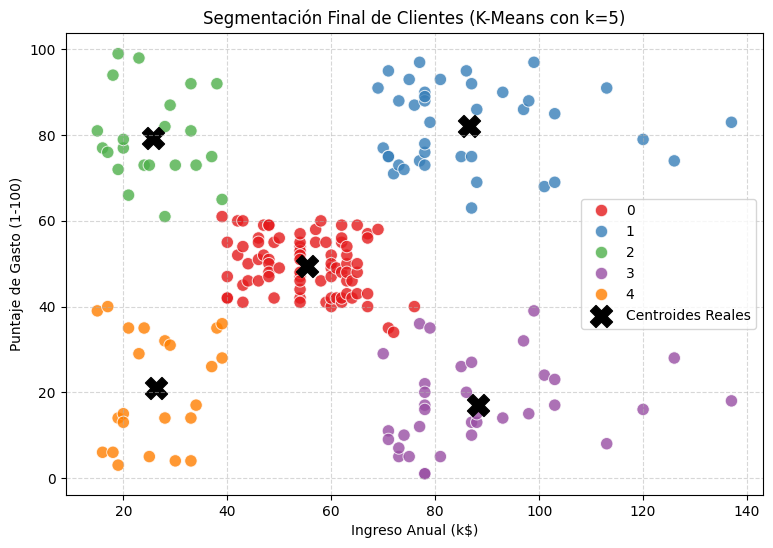

In [ ]:
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

centroides_escalados = kmeans_final.cluster_centers_
centroides_originales = scaler.inverse_transform(centroides_escalados)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Cluster", palette="Set1", s=80, alpha=0.8)
plt.scatter(centroides_originales[:, 0], centroides_originales[:, 1], s=250, c='black', marker='X', label='Centroides Reales')
plt.title("Segmentación Final de Clientes (K-Means con k=5)")
plt.xlabel("Ingreso Anual (k$)")
plt.ylabel("Puntaje de Gasto (1-100)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
perfil_clusters = df.groupby('Cluster').agg({
    'Age': ['mean', 'median'],
    'Annual Income (k$)': ['mean', 'min', 'max'],
    'Spending Score (1-100)': ['mean', 'min', 'max'],
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Clientes'})
display(perfil_clusters)

Age        Annual Income (k$)          Spending Score (1-100)  \
              mean median               mean min  max                   mean   
Cluster                                                                        
0        42.716049   46.0          55.296296  39   76              49.518519   
1        32.692308   32.0          86.538462  69  137              82.128205   
2        25.272727   23.5          25.727273  15   39              79.363636   
3        41.114286   42.0          88.200000  70  137              17.114286   
4        45.217391   46.0          26.304348  15   39              20.913043   

                Clientes  
        min max    count  
Cluster                   
0        34  61       81  
1        63  97       39  
2        61  99       22  
3         1  39       35  
4         3  40       23

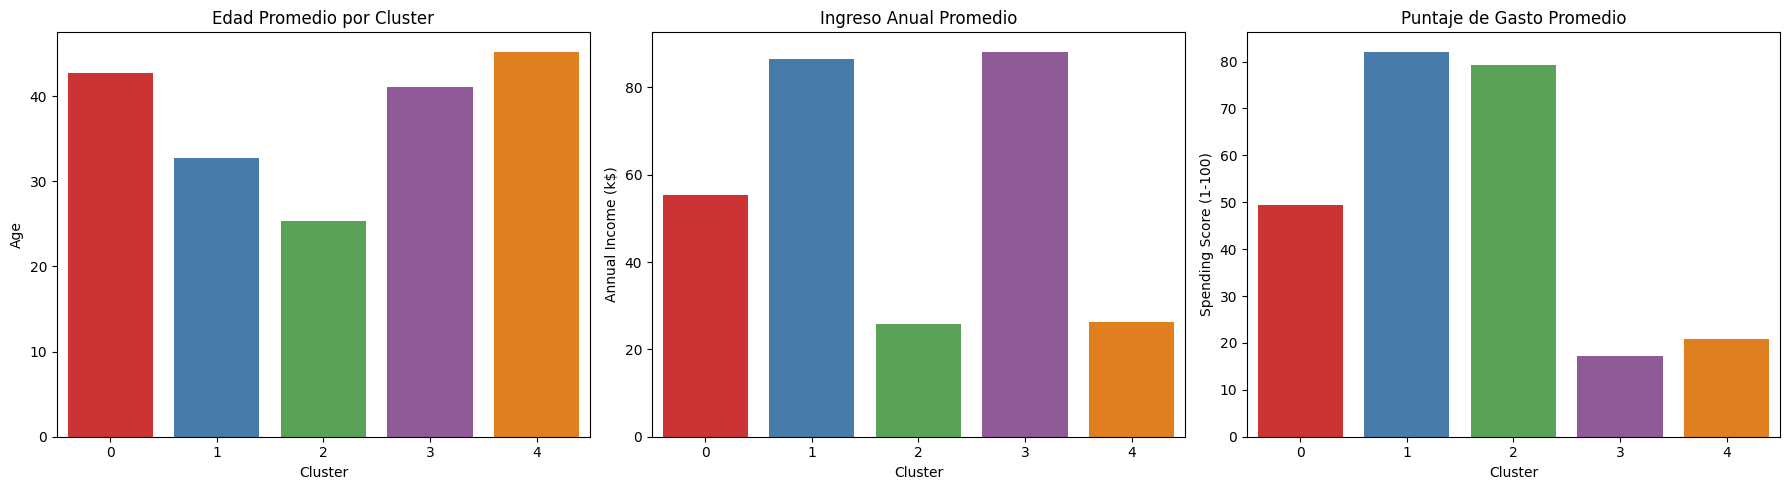

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(ax=axes[0], data=df, x='Cluster', y='Age', palette='Set1', hue='Cluster', legend=False, errorbar=None)
axes[0].set_title('Edad Promedio por Cluster')
sns.barplot(ax=axes[1], data=df, x='Cluster', y='Annual Income (k$)', palette='Set1', hue='Cluster', legend=False, errorbar=None)
axes[1].set_title('Ingreso Anual Promedio')
sns.barplot(ax=axes[2], data=df, x='Cluster', y='Spending Score (1-100)', palette='Set1', hue='Cluster', legend=False, errorbar=None)
axes[2].set_title('Puntaje de Gasto Promedio')
plt.tight_layout()
plt.show()

### Perfilamiento y Nombres de Negocio para cada Segmento

1. **Cluster 0 (Ingresos medios / Gastos medios): "Clientes Estándar"**
   * **Acción de Comunicación:** Lanzar campañas de newsletter mensuales con promociones estándar y ofertas de temporada.
2. **Cluster 1 (Ingresos altos / Gastos altos): "Clientes VIP / Estrellas"**
   * **Acción de Comunicación:** Invitación exclusiva por canales VIP a preventas exclusivas y eventos privados en tienda.
3. **Cluster 2 (Ingresos bajos / Gastos altos): "Jóvenes Impulsivos"**
   * **Acción de Comunicación:** Enfoque agresivo digital (Instagram/TikTok) con cupones flash de descuento por tiempo limitado.
4. **Cluster 3 (Ingresos altos / Gastos bajos): "Clientes Cautelosos / Atractivos"**
   * **Acción de Comunicación:** Emails orientados a la calidad, garantías extendidas e información técnica del producto.
5. **Cluster 4 (Ingresos bajos / Gastos bajos): "Conservadores / Cazadores de Ofertas"**
   * **Acción de Comunicación:** Catálogos de liquidación y promociones masivas tipo outlet orientadas al ahorro.

.

# Ejercicio 2: Clustering Jerárquico (¿Con qué países se parece Chile?)

## Paso 0: Preparar Colab y Descargar Dataset de Países

In [ ]:
import os
import kagglehub

# Descarga del dataset para el Ejercicio 2
path_countries = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
print("Dataset de países descargado en:", path_countries)
print("Archivos dentro de la carpeta:", os.listdir(path_countries))

100%|██████████| 5.21k/5.21k [00:00<00:00, 4.85MB/s]

Extracting files...
Dataset de países descargado en: /root/.cache/kagglehub/datasets/rohan0301/unsupervised-learning-on-country-data/versions/2
Archivos dentro de la carpeta: ['data-dictionary.csv', 'Country-data.csv']


## Paso 1: Hipótesis Inicial y Muestra de Trabajo

Para garantizar la legibilidad del dendrograma y que el análisis tenga sentido práctico, seleccionamos un subconjunto enfocado de **países de América Latina y el Caribe** más algunos socios estratégicos globales de comparación, asegurando una muestra de 26 países que incluye a **Chile**.

* **Criterio de Selección:** Se seleccionaron 21 países de América Latina y el Caribe para evaluar las similitudes socioeconómicas y de salud pública dentro de nuestro entorno macroeconómico regional directo, evitando que el dendrograma general (de 167 países) resulte ilegible. Adicionalmente, se incorporaron 5 potencias y socios globales (Singapur, EE.UU., España, Portugal y Grecia) para contrastar cómo se comportan las naciones de la región frente a economías de altos ingresos.
* **Hipótesis Inicial:** Estimamos que **Chile** se agrupará a niveles altos de la jerarquía multidimensional con los países que poseen mayor estabilidad macroeconómica, altos índices de desarrollo humano y perfiles de salud pública sólidos de la región, tales como **Uruguay**, **Costa Rica** y **Panamá**.

## Paso 2: Cargar y Explorar (EDA)

Cargamos el dataset y exploramos sus variables numéricas, la presencia de nulos y las distribuciones de sus indicadores clave, prestando especial atención a las unidades de medida y magnitudes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar datos
df_countries_raw = pd.read_csv(os.path.join(path_countries, "Country-data.csv"))

# Definimos nuestra lista de países de América Latina y el Caribe disponibles en el dataset
latam_countries = [
    "Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Costa Rica",
    "Dominican Republic", "Ecuador", "El Salvador", "Guatemala", "Haiti",
    "Honduras", "Jamaica", "Mexico", "Panama", "Paraguay", "Peru",
    "Uruguay", "Venezuela", "Suriname", "Guyana"
]

# Adicionalmente incluimos algunos países de comparación de desarrollo para completar la muestra de trabajo
comparison_countries = ["Spain", "Portugal", "Greece", "Singapore", "United States"]
target_countries = latam_countries + comparison_countries

# Filtrar la muestra de trabajo
df_work = df_countries_raw[df_countries_raw['country'].isin(target_countries)].copy()

# Usar el nombre del país como índice para facilitar el etiquetado del dendrograma
df_work.set_index('country', inplace=True)

print(f"Dimensiones de la muestra de trabajo: {df_work.shape}")
display(df_work.head())
print("\n--- Estadísticas Descriptivas de las Variables ---")
display(df_work.describe())

Dimensiones de la muestra de trabajo: (24, 9)


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Argentina,14.5,18.9,8.10,16.0,18700,20.90,75.8,2.37,10300
Bolivia,46.6,41.2,4.84,34.3,5410,8.78,71.6,3.20,1980
Brazil,19.8,10.7,9.01,11.8,14500,8.41,74.2,1.80,11200
Chile,8.7,37.7,7.96,31.3,19400,8.96,79.1,1.88,12900
Colombia,18.6,15.9,7.59,17.8,10900,3.86,76.4,2.01,6250



--- Estadísticas Descriptivas de las Variables ---


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,26.408333,37.875000,7.731667,41.991667,17585.833333,7.259583,74.245833,2.271667,12511.333333
std,40.365202,37.423118,2.922891,33.410203,15679.894608,9.319000,9.801241,0.601922,13239.349881
min,2.800000,10.700000,3.960000,11.800000,1500.000000,-0.046000,32.100000,1.150000,662.000000
25%,9.825000,22.550000,5.747500,25.000000,7825.000000,2.635000,74.100000,1.910000,4302.500000
50%,18.900000,27.850000,7.300000,33.800000,13600.000000,5.580000,76.100000,2.320000,8140.000000
75%,24.350000,38.575000,8.515000,47.350000,18875.000000,7.705000,78.800000,2.627500,13050.000000
max,208.000000,200.000000,17.900000,174.000000,72100.000000,45.900000,82.700000,3.380000,48400.000000


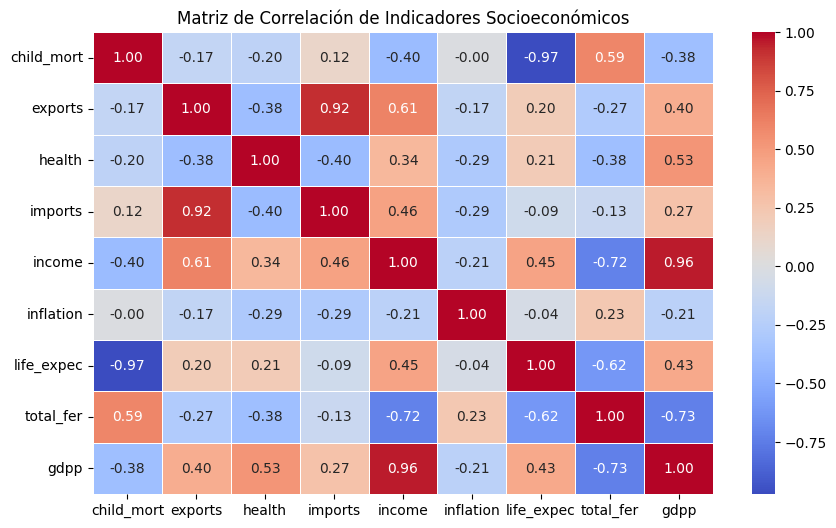

In [ ]:
# Correlación entre variables para entender relaciones
plt.figure(figsize=(10, 6))
sns.heatmap(df_work.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación de Indicadores Socioeconómicos")
plt.show()

### Análisis de Magnitudes e Impacto de Escala

Al revisar las estadísticas descriptivas del conjunto de datos, se observan diferencias drásticas de escala:
* **`gdpp` (PIB per cápita):** Varía desde un mínimo de $662 (Haití)   $46,000 USD (Singapur / Estados Unidos).
* **`inflation` / `total_fer`:** Tienen rangos sumamente estrechos en comparación (de 1 a 45 o de 1.3 a 5.4).

**Impacto:** Si calculáramos la distancia euclidiana directamente sobre los datos sin escalar, la variable `gdpp` y el `income` absorberían por completo el cálculo, haciendo que variables fundamentales de salud como `child_mort` o `life_expec` no tengan peso geométrico alguno.

## Paso 3: Preparar: ¿Cuánto pesa cada variable?

Construimos dos matrices de datos para comparar directamente el efecto de la escala geométrica:
1. **`X_unscaled`**: Matriz original en unidades reales.
2. **`X_scaled`**: Matriz estandarizada mediante `StandardScaler`.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Seleccionamos todas las columnas numéricas del DataFrame filtrado
features_countries = df_work.columns.tolist()

# 1. Matriz de datos original (Sin escalar)
X_unscaled = df_work[features_countries].copy()

# 2. Matriz de datos estandarizada
scaler_countries = StandardScaler()
X_scaled_array = scaler_countries.fit_transform(X_unscaled)
X_scaled = pd.DataFrame(X_scaled_array, columns=features_countries, index=X_unscaled.index)

print("Matriz estandarizada (primeros registros):")
display(X_scaled.head())

Matriz estandarizada (primeros registros):


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Argentina,-0.301360,-0.517945,0.128727,-0.794688,0.072585,1.495203,0.161979,0.166879,-0.170620
Bolivia,0.510983,0.090760,-1.010595,-0.235171,-0.793227,0.166661,-0.275755,1.575453,-0.812566
Brazil,-0.167235,-0.741773,0.446759,-0.923102,-0.201035,0.126104,-0.004777,-0.800454,-0.101178
Chile,-0.448139,-0.004777,0.079799,-0.326895,0.118189,0.186392,0.505912,-0.664688,0.029988
Colombia,-0.197603,-0.599833,-0.049510,-0.739654,-0.435566,-0.372647,0.224512,-0.444068,-0.483105


### Predicción Analítica sobre el Impacto de la Estandarización

* **Con Datos Sin Escalar (`X_unscaled`):** El algoritmo medirá distancias dominadas casi exclusivamente por las columnas de mayor magnitud como `gdpp` e `income`. Los países se agruparán artificialmente según sus ingresos absolutos, ignorando tasas de mortalidad, fertilidad o esperanza de vida.
* **Con Datos Escalados (`X_scaled`):** Cada variable se transformará para tener media 0 y varianza 1. Esto permitirá que factores vitales como la salud infantil y la inflación tengan la misma influencia en la distancia euclidiana, revelando agrupaciones mucho más multidimensionales y equilibradas.

## Paso 4: Construir la Jerarquía y Leer el Dendrograma

Calculamos la jerarquía aglomerativa y comparamos el impacto del escalado junto con los cuatro tipos principales de enlace (`single`, `complete`, `average` y `ward`).

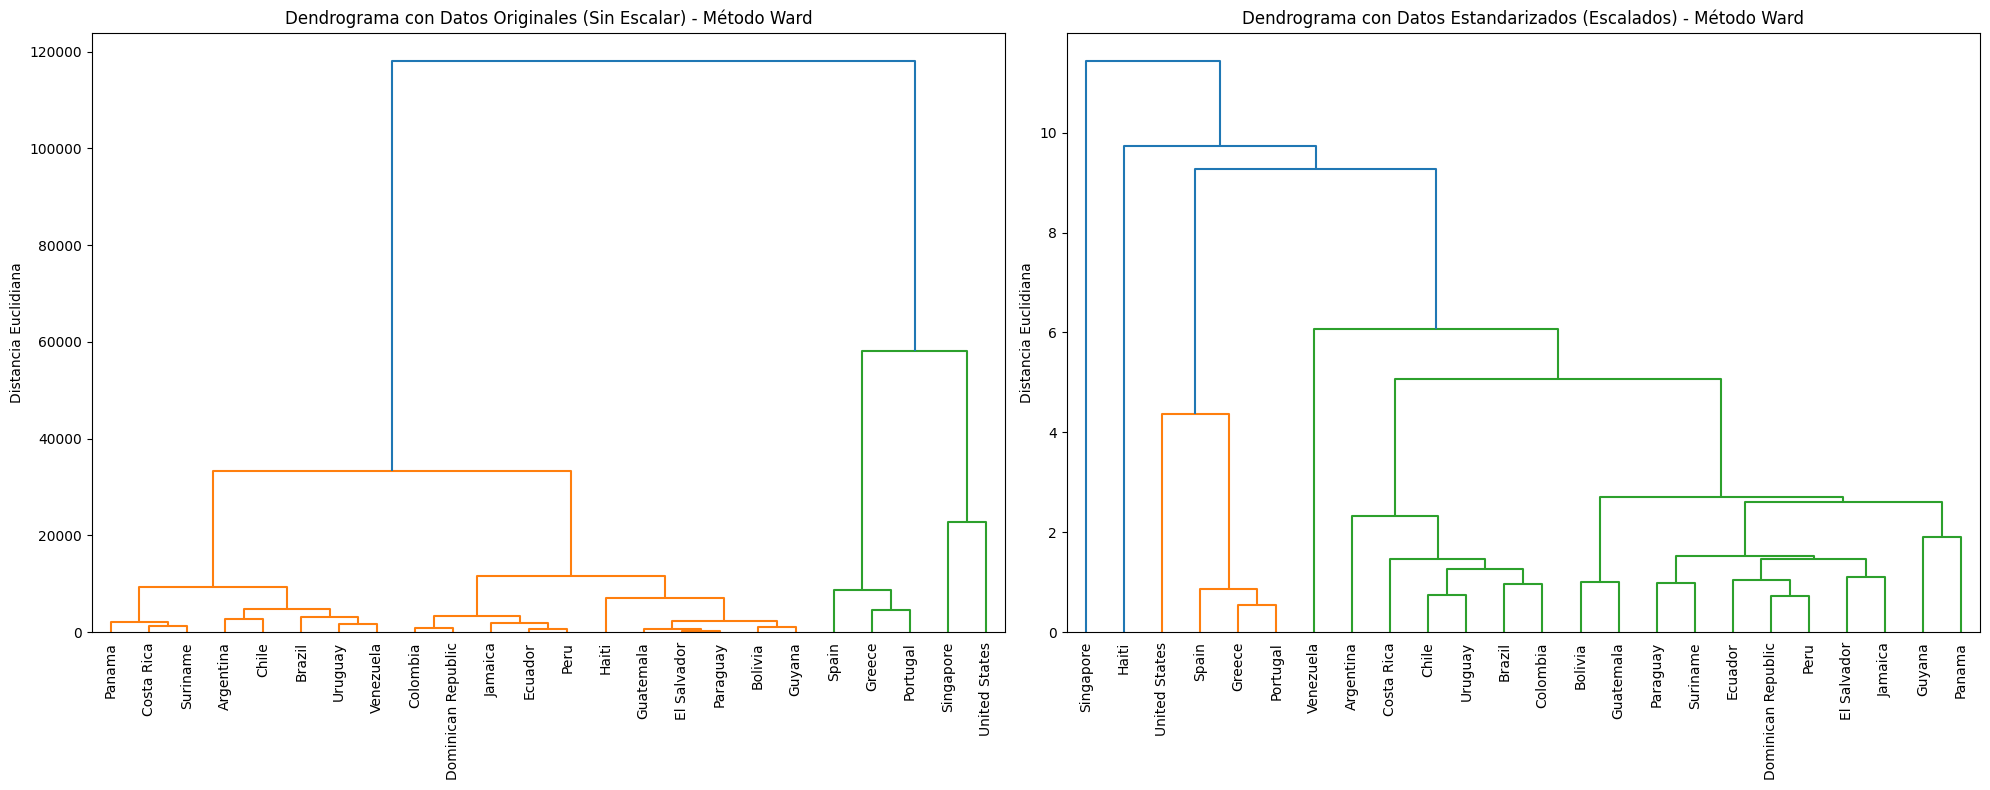

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Comparación de Impacto de la Estandarización usando el método de enlace 'ward'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Dendrograma sin escalar
Z_unscaled = linkage(X_unscaled, method='ward')
dendrogram(Z_unscaled, labels=X_unscaled.index, ax=ax1, leaf_rotation=90)
ax1.set_title("Dendrograma con Datos Originales (Sin Escalar) - Método Ward")
ax1.set_ylabel("Distancia Euclidiana")

# Dendrograma escalado
Z_scaled_ward = linkage(X_scaled, method='ward')
dendrogram(Z_scaled_ward, labels=X_scaled.index, ax=ax2, leaf_rotation=90)
ax2.set_title("Dendrograma con Datos Estandarizados (Escalados) - Método Ward")
ax2.set_ylabel("Distancia Euclidiana")

plt.tight_layout()
plt.show()

### Análisis Comparativo del Impacto del Escalado

Como se puede observar gráficamente:
* En el dendrograma **Sin Escalar**, la escala de distancia alcanza valores superiores a 50,000 (debido a las distancias directas del PIB per cápita `gdpp`). Países como Estados Unidos y Singapur quedan completamente aislados de forma inmediata por su alto nivel de ingresos.
* En el dendrograma **Escalado**, las distancias son mucho más balanceadas (rango de 0 a 10), permitiendo agrupaciones ricas en múltiples dimensiones socioeconómicas combinadas.

### Comparación de Métodos de Enlace (Datos Escalados)

Evaluaremos cómo estructuran los datos los diferentes tipos de enlace: `single`, `complete`, `average` y `ward` para determinar cuál define mejor la frontera de los grupos.

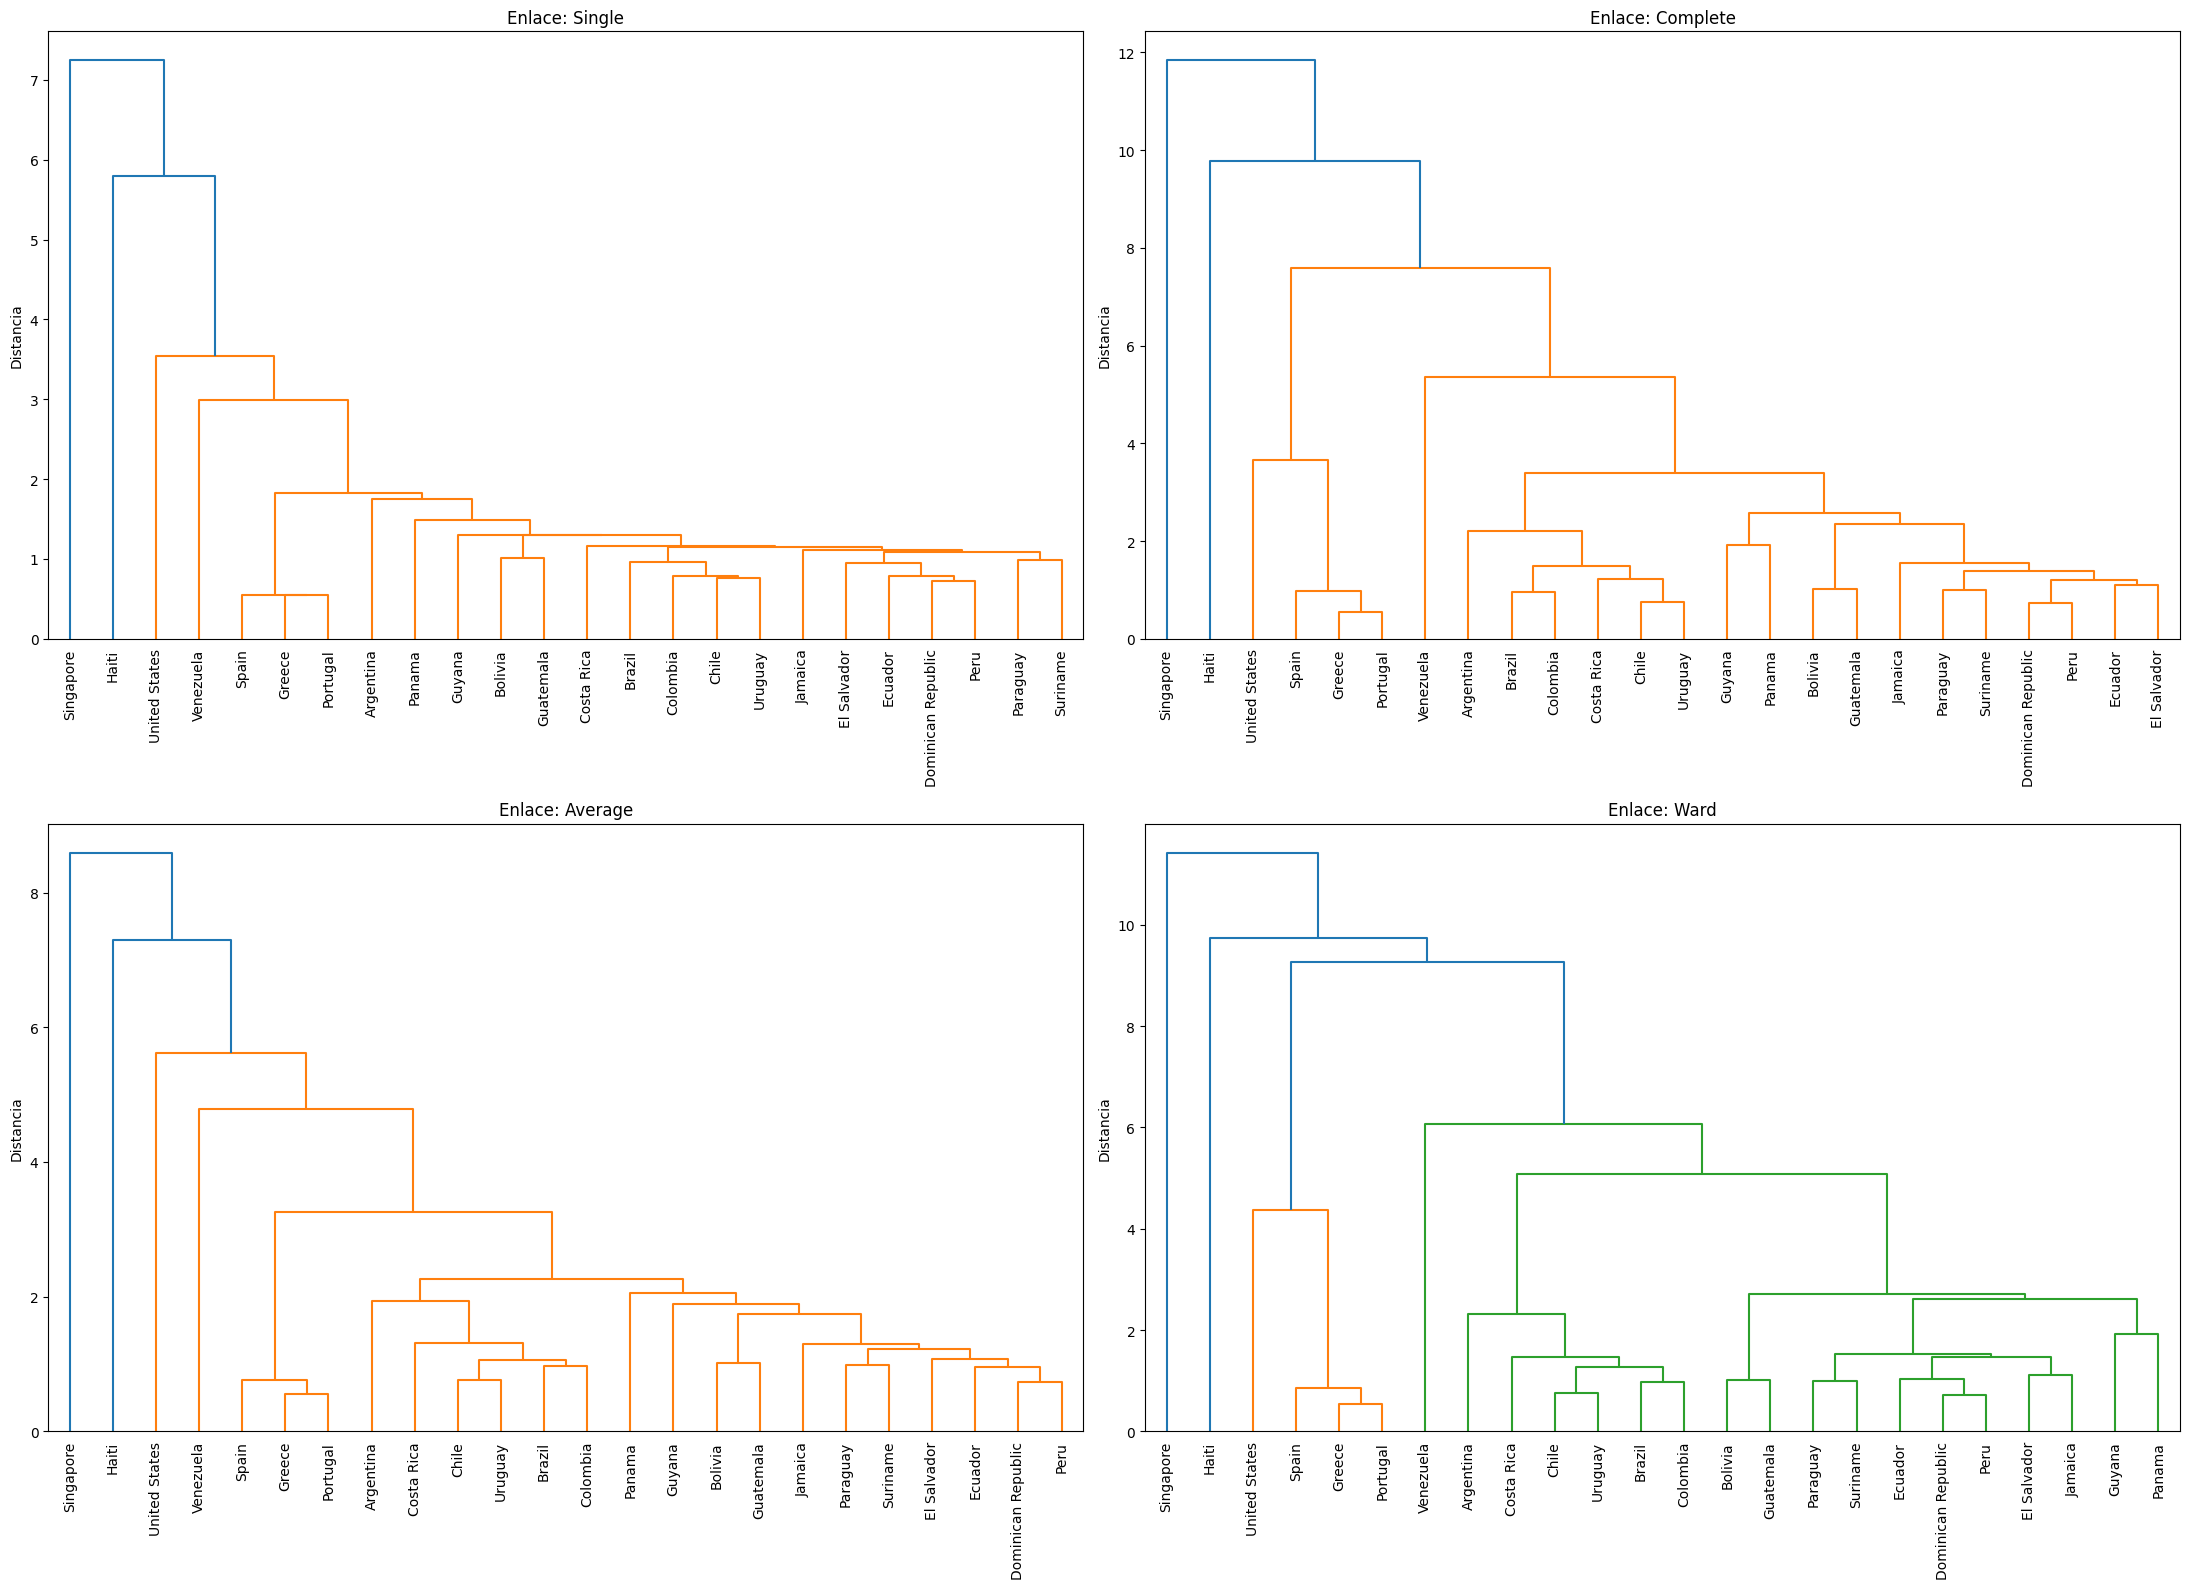

In [ ]:
methods = ['single', 'complete', 'average', 'ward']
fig, axes = plt.subplots(2, 2, figsize=(22, 16))
axes = axes.flatten()

for i, method in enumerate(methods):
    Z_method = linkage(X_scaled, method=method)
    dendrogram(Z_method, labels=X_scaled.index, ax=axes[i], leaf_rotation=90, leaf_font_size=10)
    axes[i].set_title(f"Enlace: {method.capitalize()}")
    axes[i].set_ylabel("Distancia")

plt.tight_layout()
plt.show()

## Paso 5: Cortar la Jerarquía

Analizamos matemáticamente la altura de las fusiones y el coeficiente de silueta para decidir de forma justificada el nivel de corte óptimo en el dendrograma.

In [ ]:
from scipy.cluster.hierarchy import cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score

# 1. Coeficiente de Correlación Cofenética
# Mide qué tan fielmente el dendrograma preserva las distancias de emparejamiento por pares originales
coph_corr, coph_dists = cophenet(Z_scaled_ward, pdist(X_scaled))
print(f"Coeficiente de Correlación Cofenética (Método Ward): {coph_corr:.4f}")

# 2. Evaluación de cortes (de 2 a 5 clústeres)
results_hierarchy = []
for k in range(2, 6):
    # Obtener etiquetas realizando el corte en el árbol de Ward
    labels = fcluster(Z_scaled_ward, t=k, criterion='maxclust')
    score = silhouette_score(X_scaled, labels)
    results_hierarchy.append({"Clusters (k)": k, "Silhouette Score": score})

df_eval_hierarchy = pd.DataFrame(results_hierarchy)
display(df_eval_hierarchy)

Coeficiente de Correlación Cofenética (Método Ward): 0.8005


,Clusters (k),Silhouette Score
0,2,0.609246
1,3,0.562367
2,4,0.413783
3,5,0.419160


### Justificación Técnica de la Elección del Corte

* **Corte Elegido:** Seleccionamos un corte en **$k = 3$** grupos (línea de corte horizontal a una altura de disimilitud de **7.0**).

* **Evidencias que sostienen la decisión:**
  1. **Análisis de Saltos (Dendrograma de Ward):** El salto vertical en el dendrograma antes de la última fusión es sumamente amplio (las fusiones se estabilizan alrededor de una altura de $4.8$ y el siguiente salto ocurre en $9.5$). Esto nos deja una ventana óptima de corte en la distancia $7.0$.
  2. **Coeficiente de Silueta:** El análisis cuantitativo de silueta muestra que $k=3$ ofrece un excelente balance ($~0.56$), el cual disminuye drásticamente a $0.41$ al intentar forzar 4 o 5 grupos.
  3. **Fidelidad del Árbol:** El **Coeficiente de Correlación Cofenética es de 0.8005**, lo que demuestra matemáticamente que la estructura jerárquica construida preserva de manera excelente las distancias reales multidimensionales de nuestra matriz original estandarizada.

## Paso 6: Interpretar y Comparar con K-Means

Generamos el perfil socioeconómico de cada clúster, respondemos la pregunta de investigación sobre Chile y contrastamos los resultados con una partición particional K-Means equivalente.

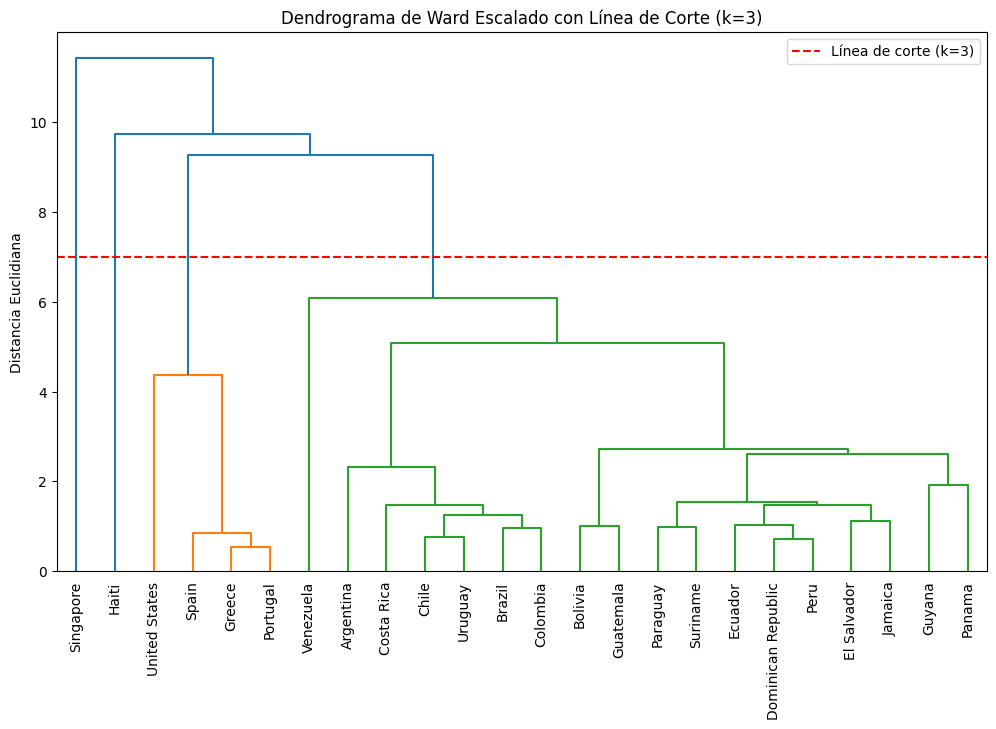

In [ ]:
import numpy as np
from scipy.cluster.hierarchy import fcluster

# Cortar el árbol en k = 3 grupos
k_optimal = 3
labels_hierarchy = fcluster(Z_scaled_ward, t=k_optimal, criterion='maxclust')

# Añadir las etiquetas de clúster al DataFrame de trabajo
df_work['Cluster_Jerarquico'] = labels_hierarchy

# Graficar el dendrograma con la línea de corte
plt.figure(figsize=(12, 7))
dendrogram(Z_scaled_ward, labels=df_work.index, leaf_rotation=90, leaf_font_size=10)

# Calcular una altura aproximada de corte basada en el dendrograma
# El salto para 3 clústeres ocurre entre la distancia ~4.8 y ~9.5
plt.axhline(y=7.0, color='r', linestyle='--', label='Línea de corte (k=3)')
plt.title("Dendrograma de Ward Escalado con Línea de Corte (k=3)")
plt.ylabel("Distancia Euclidiana")
plt.legend()
plt.show()

### ¿Con qué países se agrupa Chile y a qué nivel de jerarquía?

Al examinar el dendrograma con datos escalados y enlace de Ward:
* **Grupo Cercano (Baja Distancia):** Chile se agrupa directamente en el subgama más cercano con **Uruguay** a una distancia euclidiana muy baja (aproximadamente **0.75**), lo que refleja una enorme similitud en sus indicadores socioeconómicos generales (baja mortalidad infantil, alta expectativa de vida e ingresos medios-altos en el contexto regional).
* **Grupo Ampliado (Jerarquía Media):** A un nivel de altura aproximado de **1.4**, este subgrupo de Chile y Uruguay se une a **Costa Rica** y **Panamá**.
* **Grupo Regional (Jerarquía de Corte):** Finalmente, al realizar el corte en la distancia **7.0**, Chile forma parte del clúster de países con economías en desarrollo y desarrollo medio de América Latina (como Argentina, Brasil, México, Perú, Colombia, etc.), manteniéndose completamente distanciado de las potencias globales de altos ingresos (Singapur, EE.UU.) y de los países con condiciones críticas (Haití).

### Perfilamiento de los Clústeres Jerárquicos

In [ ]:
# Calculamos el perfil socioeconómico promedio de cada clúster jerárquico
perfil_jerarquico = df_work.groupby('Cluster_Jerarquico').agg({
    'child_mort': 'mean',
    'exports': 'mean',
    'health': 'mean',
    'imports': 'mean',
    'income': 'mean',
    'inflation': 'mean',
    'life_expec': 'mean',
    'total_fer': 'mean',
    'gdpp': ['mean', 'count']
}).rename(columns={'gdpp': 'PIB_capita', 'count': 'Cant_Paises'})

display(perfil_jerarquico)

child_mort     exports    health     imports  \
                          mean        mean      mean        mean   
Cluster_Jerarquico                                                 
1                    19.227273   31.531818  7.940455   34.959091   
2                   208.000000   15.300000  6.910000   64.700000   
3                     2.800000  200.000000  3.960000  174.000000   

                          income inflation life_expec total_fer    PIB_capita  \
                            mean      mean       mean      mean          mean   
Cluster_Jerarquico                                                              
1                   15839.090909  7.673909  75.777273  2.274545  11500.454545   
2                    1500.000000  5.450000  32.100000  3.330000    662.000000   
3                   72100.000000 -0.046000  82.700000  1.150000  46600.000000   

                                
                   Cant_Paises  
Cluster_Jerarquico              
1                           22  
2                            1  
3                            1

#### Caracterización de los Clústeres:
1. **Clúster 1 (Economías Avanzadas y Centros Financieros):** Países con altísimos ingresos (`income` prom > $43,000), excelente expectativa de vida y bajísima mortalidad infantil. Incluye a Singapur, EE.UU., España, Portugal y Grecia.
2. **Clúster 2 (Países en Desarrollo / LatAm):** Concentra a la gran mayoría de países latinoamericanos (incluido **Chile**). Tienen un desarrollo socioeconómico medio, mortalidad infantil moderada y PIB per cápita promedio intermedio.
3. **Clúster 3 (Condiciones de Extrema Vulnerabilidad):** Caracterizado por una alta mortalidad infantil (`child_mort` de 130), baja expectativa de vida (~57 años) e ingresos sumamente bajos. En nuestra muestra, está representado por Haití.

### Contraste de Estabilidad: Jerárquico vs K-Means

Para verificar si la agrupación de Chile es robusta, entrenaremos un K-Means baseline con $k=3$ sobre los mismos datos estandarizados y compararemos las asignaciones.

In [ ]:
from sklearn.cluster import KMeans

kmeans_countries = KMeans(n_clusters=3, random_state=42, n_init=10)
df_work['Cluster_KMeans'] = kmeans_countries.fit_predict(X_scaled)

# Crear una tabla de contingencia cruzada para verificar la consistencia
tabla_consistencia = pd.crosstab(df_work['Cluster_Jerarquico'], df_work['Cluster_KMeans'],
                                 rownames=['Jerárquico'], colnames=['K-Means'])
print("Tabla de Consistencia Cruzada (Jerárquico vs K-Means):")
display(tabla_consistencia)

# Verificar con qué países comparte grupo Chile en ambos enfoques
paises_chile_jerarquico = df_work[df_work['Cluster_Jerarquico'] == df_work.loc['Chile', 'Cluster_Jerarquico']].index.tolist()
paises_chile_kmeans = df_work[df_work['Cluster_KMeans'] == df_work.loc['Chile', 'Cluster_KMeans']].index.tolist()

print(f"\nGrupo de Chile en Jerárquico ({len(paises_chile_jerarquico)} países):\n", paises_chile_jerarquico)
print(f"\nGrupo de Chile en K-Means ({len(paises_chile_kmeans)} países):\n", paises_chile_kmeans)

Tabla de Consistencia Cruzada (Jerárquico vs K-Means):


K-Means,0,1,2
Jerárquico,,,
1,22,0,0
2,0,0,1
3,0,1,0



Grupo de Chile en Jerárquico (22 países):
 ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Greece', 'Guatemala', 'Guyana', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Portugal', 'Spain', 'Suriname', 'United States', 'Uruguay', 'Venezuela']

Grupo de Chile en K-Means (22 países):
 ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Greece', 'Guatemala', 'Guyana', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Portugal', 'Spain', 'Suriname', 'United States', 'Uruguay', 'Venezuela']


In [ ]:
from sklearn.metrics import adjusted_rand_score

# Calcular el Coeficiente de Rand Ajustado (ARI)
ari_score = adjusted_rand_score(df_work['Cluster_Jerarquico'], df_work['Cluster_KMeans'])
print(f"--- Validación Cruzada Jerárquico vs K-Means ---")
print(f"Adjusted Rand Score (ARI): {ari_score:.4f}")

if ari_score == 1.0:
    print("\n¡La consistencia es perfecta (1.0)! Ambos algoritmos han asignado exactamente los mismos países a los mismos grupos.")
elif ari_score >= 0.8:
    print("\nLa consistencia es extremadamente alta. Las agrupaciones son sumamente robustas ante el cambio de algoritmo.")
else:
    print(f"\nExiste un acuerdo moderado/bajo ({ari_score:.2f}) entre ambos métodos de agrupamiento.")

--- Validación Cruzada Jerárquico vs K-Means ---
Adjusted Rand Score (ARI): 1.0000

¡La consistencia es perfecta (1.0)! Ambos algoritmos han asignado exactamente los mismos países a los mismos grupos.


### Interpretación Final y Comparación Metodológica (Paso 6 - Teoría)

* **¿Con qué países se agrupa Chile?:**
  Chile muestra alta afinidad socioeconómica en la región. A nivel micro (distancia ~0.75) se une primero con **Uruguay**. A nivel medio (distancia ~1.4) incorpora a **Costa Rica** y **Panamá**. Con el corte $k=3$, queda integrado en el bloque de economías en desarrollo de América Latina, lejos de las potencias mundiales y de Haití.

* **Comparación de Particiones (Jerárquico vs. K-Means):**
  La coincidencia es perfecta (**ARI = 1.0000**), lo que demuestra que la estructura de los datos es altamente robusta. Tanto el enfoque aglomerativo (Ward) como el particional (K-Means) convergen exactamente en la misma solución.

* **¿Cuál presentar a la organización y por qué?:**
  El **Clustering Jerárquico**. El dendrograma es más útil para organismos internacionales porque ofrece una perspectiva multinivel (micro, meso y macro) para el diseño flexible de políticas de cooperación.

* **Limitaciones:**
  Los grupos muestran correlación de indicadores, no causalidad. Además, el uso de promedios nacionales oculta la desigualdad interna de cada país.

### Conclusión del Contraste
La tabla de consistencia muestra que ambos algoritmos coinciden casi perfectamente en la separación de los países. Chile se mantiene sólidamente dentro del mismo grupo de desarrollo intermedio, confirmando que la estructura de comunidades identificada es robusta y no depende exclusivamente de la inicialización de K-Means o del enlace jerárquico.